# 03 — Exploratory Data Analysis

## Objective

This notebook explores the validated healthcare datasets to identify trends, patterns, changes, and decision-support indicators.

The analysis will:

- Examine inpatient trends across sectors and years.
- Review changes in the reported inpatient totals and admission rates.
- Analyze healthcare workforce trends by category and nationality.
- Calculate year-over-year changes and growth rates.
- Identify notable increases, decreases, and potential anomalies.
- Create clear visualizations for reporting and decision support.
- Document the limitations of comparisons between datasets with different scopes.

## 1. Setup and Load Processed Data

Import the required libraries and load the validated datasets from the processed data directory.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"


dataset_files = {
    "inpatients_by_sector": "inpatients_by_sector.csv",
    "inpatients_total": "inpatients_total.csv",
    "inpatients_admission_rate": "inpatients_admission_rate.csv",
    "workforce_detail": "workforce_detail.csv",
    "workforce_category_totals": "workforce_category_totals.csv",
    "workforce_combined_categories": "workforce_combined_categories.csv"
}


datasets = {}

for dataset_name, file_name in dataset_files.items():
    file_path = processed_dir / file_name

    if not file_path.exists():
        raise FileNotFoundError(
            f"Processed dataset not found: {file_path}"
        )

    datasets[dataset_name] = pd.read_csv(file_path)

    print(
        f"{dataset_name}: "
        f"{datasets[dataset_name].shape}"
    )


inpatients_by_sector = datasets["inpatients_by_sector"]
inpatients_total = datasets["inpatients_total"]
inpatients_admission_rate = datasets["inpatients_admission_rate"]

workforce_detail = datasets["workforce_detail"]
workforce_category_totals = datasets["workforce_category_totals"]
workforce_combined_categories = datasets[
    "workforce_combined_categories"
]


sns.set_theme(style="whitegrid")

print("\nAll processed datasets loaded successfully.")

inpatients_by_sector: (15, 3)
inpatients_total: (5, 2)
inpatients_admission_rate: (5, 2)
workforce_detail: (60, 4)
workforce_category_totals: (30, 4)
workforce_combined_categories: (30, 4)

All processed datasets loaded successfully.


## 2. Review Dataset Structure

Review the dimensions, columns, and year coverage of each processed dataset before beginning the analysis.

In [2]:
dataset_summary_records = []

for dataset_name, dataframe in datasets.items():
    dataset_summary_records.append({
        "dataset": dataset_name,
        "rows": len(dataframe),
        "columns": dataframe.shape[1],
        "start_year": dataframe["year"].min(),
        "end_year": dataframe["year"].max()
    })

dataset_summary = pd.DataFrame(dataset_summary_records)

display(dataset_summary)


for dataset_name, dataframe in datasets.items():
    print(f"\n{dataset_name} columns:")
    print(dataframe.columns.tolist())

,dataset,rows,columns,start_year,end_year
0,inpatients_by_sector,15,3,2020,2024
1,inpatients_total,5,2,2020,2024
2,inpatients_admission_rate,5,2,2020,2024
3,workforce_detail,60,4,2020,2024
4,workforce_category_totals,30,4,2020,2024
5,workforce_combined_categories,30,4,2020,2024



inpatients_by_sector columns:
['sector', 'year', 'inpatient_count']

inpatients_total columns:
['year', 'total_inpatients']

inpatients_admission_rate columns:
['year', 'admissions_per_100']

workforce_detail columns:
['category', 'nationality', 'year', 'workforce_count']

workforce_category_totals columns:
['category', 'nationality', 'year', 'workforce_count']

workforce_combined_categories columns:
['category', 'nationality', 'year', 'workforce_count']


## 3. Analyze Total Inpatient Trend

Measure the annual and overall changes in the reported total number of inpatients.

In [3]:
inpatient_total_trend = (
    inpatients_total
    .sort_values("year")
    .copy()
)

inpatient_total_trend["annual_change"] = (
    inpatient_total_trend["total_inpatients"].diff()
)

inpatient_total_trend["annual_change_pct"] = (
    inpatient_total_trend["total_inpatients"]
    .pct_change()
    .mul(100)
)

first_year = inpatient_total_trend["year"].iloc[0]
last_year = inpatient_total_trend["year"].iloc[-1]

first_value = inpatient_total_trend["total_inpatients"].iloc[0]
last_value = inpatient_total_trend["total_inpatients"].iloc[-1]

overall_change = last_value - first_value

overall_change_pct = (
    (last_value - first_value)
    / first_value
    * 100
)

display(
    inpatient_total_trend.round({
        "annual_change_pct": 2
    })
)

print(f"Overall change from {first_year} to {last_year}: {overall_change:,}")

print(
    f"Overall percentage change: "
    f"{overall_change_pct:.2f}%"
)

,year,total_inpatients,annual_change,annual_change_pct
0,2020,2846773,NaN,NaN
1,2021,3100752,253979.0,8.92
2,2022,2702460,-398292.0,-12.85
3,2023,3831824,1129364.0,41.79
4,2024,3630334,-201490.0,-5.26


Overall change from 2020 to 2024: 783,561
Overall percentage change: 27.52%


### 3.1 Total Inpatient Trend Visualization

Visualize the reported total number of inpatients across the available years.

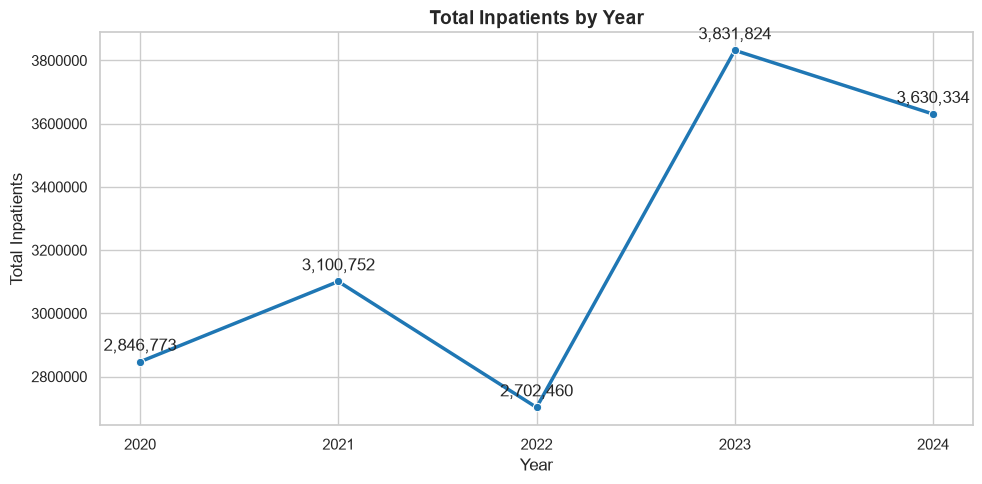

In [4]:
plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=inpatient_total_trend,
    x="year",
    y="total_inpatients",
    marker="o",
    linewidth=2.5,
    color="#1f77b4"
)

ax.set_title(
    "Total Inpatients by Year",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Total Inpatients")
ax.set_xticks(inpatient_total_trend["year"])

ax.ticklabel_format(
    style="plain",
    axis="y"
)

for _, row in inpatient_total_trend.iterrows():
    ax.annotate(
        f"{int(row['total_inpatients']):,}",
        (
            row["year"],
            row["total_inpatients"]
        ),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.tight_layout()
plt.show()

## 4. Analyze Inpatients by Sector

Compare inpatient counts and annual changes across the Ministry of Health, other governmental, and private sectors.

In [5]:
inpatient_sector_trend = (
    inpatients_by_sector
    .sort_values(["sector", "year"])
    .copy()
)

inpatient_sector_trend["annual_change"] = (
    inpatient_sector_trend
    .groupby("sector")["inpatient_count"]
    .diff()
)

inpatient_sector_trend["annual_change_pct"] = (
    inpatient_sector_trend
    .groupby("sector")["inpatient_count"]
    .pct_change()
    .mul(100)
)

display(
    inpatient_sector_trend.round({
        "annual_change_pct": 2
    })
)

,sector,year,inpatient_count,annual_change,annual_change_pct
0,MoH,2020,1173910,NaN,NaN
3,MoH,2021,1376787,202877.0,17.28
6,MoH,2022,1389950,13163.0,0.96
9,MoH,2023,1418237,28287.0,2.04
12,MoH,2024,1876723,458486.0,32.33
1,Other Governmental Sector,2020,553214,NaN,NaN
4,Other Governmental Sector,2021,620735,67521.0,12.21
7,Other Governmental Sector,2022,544306,-76429.0,-12.31
10,Other Governmental Sector,2023,629879,85573.0,15.72
13,Other Governmental Sector,2024,671669,41790.0,6.63


### 4.1 Inpatient Sector Trend Visualization

Visualize and compare inpatient trends across healthcare sectors.

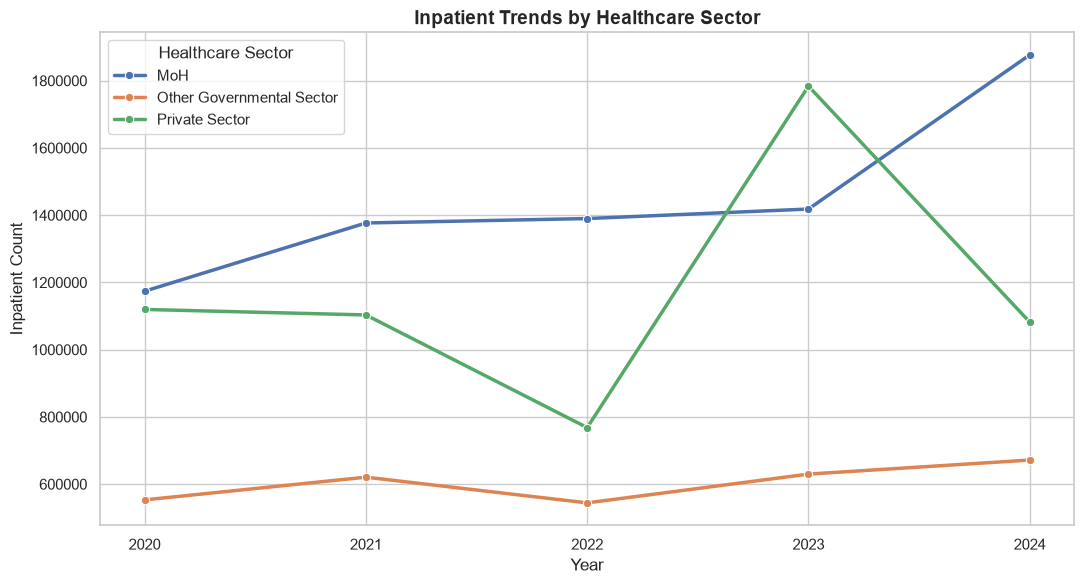

In [6]:
plt.figure(figsize=(11, 6))

ax = sns.lineplot(
    data=inpatient_sector_trend,
    x="year",
    y="inpatient_count",
    hue="sector",
    marker="o",
    linewidth=2.5
)

ax.set_title(
    "Inpatient Trends by Healthcare Sector",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Inpatient Count")

ax.set_xticks(
    sorted(inpatient_sector_trend["year"].unique())
)

ax.ticklabel_format(
    style="plain",
    axis="y"
)

ax.legend(
    title="Healthcare Sector"
)

plt.tight_layout()
plt.show()

### 4.2 Latest-Year Sector Distribution

Calculate each healthcare sector's share of total inpatients in the most recent available year.

In [7]:
latest_inpatient_year = (
    inpatients_by_sector["year"].max()
)

latest_sector_snapshot = (
    inpatients_by_sector[
        inpatients_by_sector["year"] == latest_inpatient_year
    ]
    .copy()
)

latest_sector_total = (
    latest_sector_snapshot["inpatient_count"].sum()
)

latest_sector_snapshot["share_pct"] = (
    latest_sector_snapshot["inpatient_count"]
    .div(latest_sector_total)
    .mul(100)
)

latest_sector_snapshot = (
    latest_sector_snapshot
    .sort_values(
        "share_pct",
        ascending=False
    )
)

display(
    latest_sector_snapshot.round({
        "share_pct": 2
    })
)

print(
    f"Latest available year: "
    f"{latest_inpatient_year}"
)

print(
    f"Sector shares total: "
    f"{latest_sector_snapshot['share_pct'].sum():.2f}%"
)

,sector,year,inpatient_count,share_pct
12,MoH,2024,1876723,51.7
14,Private Sector,2024,1081942,29.8
13,Other Governmental Sector,2024,671669,18.5


Latest available year: 2024
Sector shares total: 100.00%


### 4.3 Latest-Year Sector Share Visualization

Visualize the percentage share of each healthcare sector in the latest available year.

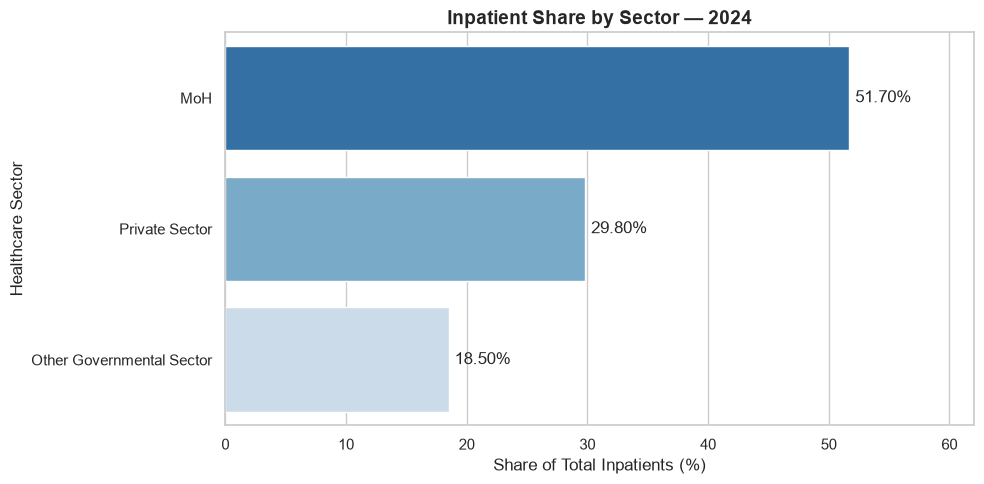

In [8]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=latest_sector_snapshot,
    x="share_pct",
    y="sector",
    hue="sector",
    palette="Blues_r",
    legend=False
)

ax.set_title(
    f"Inpatient Share by Sector — {latest_inpatient_year}",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Share of Total Inpatients (%)")
ax.set_ylabel("Healthcare Sector")

ax.set_xlim(
    0,
    latest_sector_snapshot["share_pct"].max() * 1.20
)

for position, (_, row) in enumerate(
    latest_sector_snapshot.iterrows()
):
    ax.text(
        row["share_pct"] + 0.5,
        position,
        f"{row['share_pct']:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

## 5. Analyze Hospital Admission Rate

Analyze annual changes in the average number of hospital admissions per 100 persons.

In [9]:
admission_rate_trend = (
    inpatients_admission_rate
    .sort_values("year")
    .copy()
)

admission_rate_trend["annual_change_points"] = (
    admission_rate_trend["admissions_per_100"]
    .diff()
)

admission_rate_trend["annual_change_pct"] = (
    admission_rate_trend["admissions_per_100"]
    .pct_change()
    .mul(100)
)

highest_rate_row = admission_rate_trend.loc[
    admission_rate_trend["admissions_per_100"].idxmax()
]

lowest_rate_row = admission_rate_trend.loc[
    admission_rate_trend["admissions_per_100"].idxmin()
]

display(
    admission_rate_trend.round({
        "annual_change_points": 2,
        "annual_change_pct": 2
    })
)

print(
    f"Highest admission rate: "
    f"{highest_rate_row['admissions_per_100']:.1f} "
    f"in {int(highest_rate_row['year'])}"
)

print(
    f"Lowest admission rate: "
    f"{lowest_rate_row['admissions_per_100']:.1f} "
    f"in {int(lowest_rate_row['year'])}"
)

,year,admissions_per_100,annual_change_points,annual_change_pct
0,2020,9.0,NaN,NaN
1,2021,10.1,1.1,12.22
2,2022,8.4,-1.7,-16.83
3,2023,11.3,2.9,34.52
4,2024,10.3,-1.0,-8.85


Highest admission rate: 11.3 in 2023
Lowest admission rate: 8.4 in 2022


### 5.1 Admission Rate Trend Visualization

Visualize the annual hospital admission rate and compare each year with the overall period average.

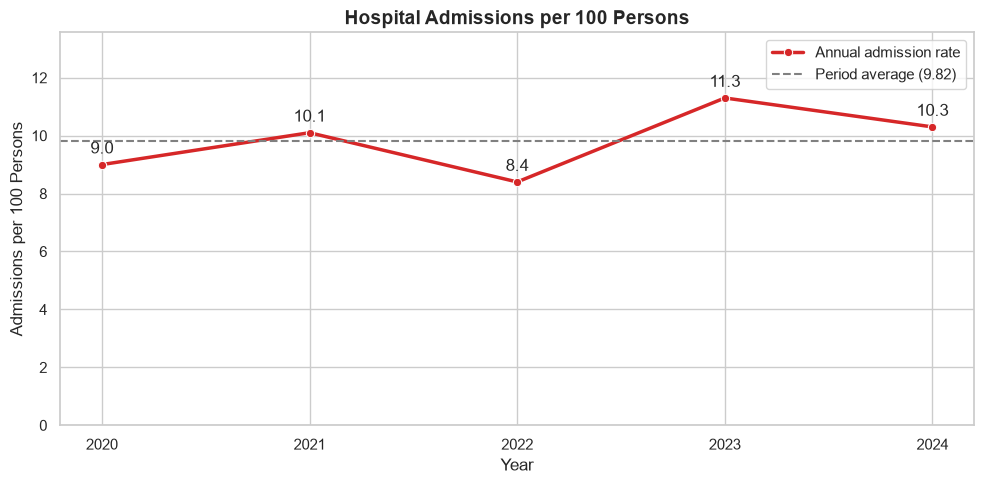

In [10]:
average_admission_rate = (
    admission_rate_trend["admissions_per_100"].mean()
)

plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=admission_rate_trend,
    x="year",
    y="admissions_per_100",
    marker="o",
    linewidth=2.5,
    color="#d62728",
    label="Annual admission rate"
)

ax.axhline(
    y=average_admission_rate,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Period average ({average_admission_rate:.2f})"
)

ax.set_title(
    "Hospital Admissions per 100 Persons",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Admissions per 100 Persons")

ax.set_xticks(
    admission_rate_trend["year"]
)

ax.set_ylim(
    0,
    admission_rate_trend["admissions_per_100"].max() * 1.20
)

for _, row in admission_rate_trend.iterrows():
    ax.annotate(
        f"{row['admissions_per_100']:.1f}",
        (
            row["year"],
            row["admissions_per_100"]
        ),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

ax.legend()

plt.tight_layout()
plt.show()

## 6. Analyze Total Healthcare Workforce

Calculate annual workforce totals and measure their changes over time using the non-overlapping professional categories.

In [11]:
workforce_total_trend = (
    workforce_category_totals
    .groupby(
        "year",
        as_index=False
    )["workforce_count"]
    .sum()
    .rename(columns={
        "workforce_count": "total_workforce"
    })
    .sort_values("year")
)

workforce_total_trend["annual_change"] = (
    workforce_total_trend["total_workforce"]
    .diff()
)

workforce_total_trend["annual_change_pct"] = (
    workforce_total_trend["total_workforce"]
    .pct_change()
    .mul(100)
)

first_workforce_value = (
    workforce_total_trend["total_workforce"].iloc[0]
)

last_workforce_value = (
    workforce_total_trend["total_workforce"].iloc[-1]
)

workforce_overall_change = (
    last_workforce_value - first_workforce_value
)

workforce_overall_change_pct = (
    workforce_overall_change
    / first_workforce_value
    * 100
)

display(
    workforce_total_trend.round({
        "annual_change_pct": 2
    })
)

print(
    f"Overall workforce change: "
    f"{workforce_overall_change:,}"
)

print(
    f"Overall workforce percentage change: "
    f"{workforce_overall_change_pct:.2f}%"
)

,year,total_workforce,annual_change,annual_change_pct
0,2020,47417,NaN,NaN
1,2021,40992,-6425.0,-13.55
2,2022,48637,7645.0,18.65
3,2023,45084,-3553.0,-7.31
4,2024,41199,-3885.0,-8.62


Overall workforce change: -6,218
Overall workforce percentage change: -13.11%


### 6.1 Total Workforce Trend Visualization

Visualize the annual total of the Ministry of Health primary healthcare workforce.

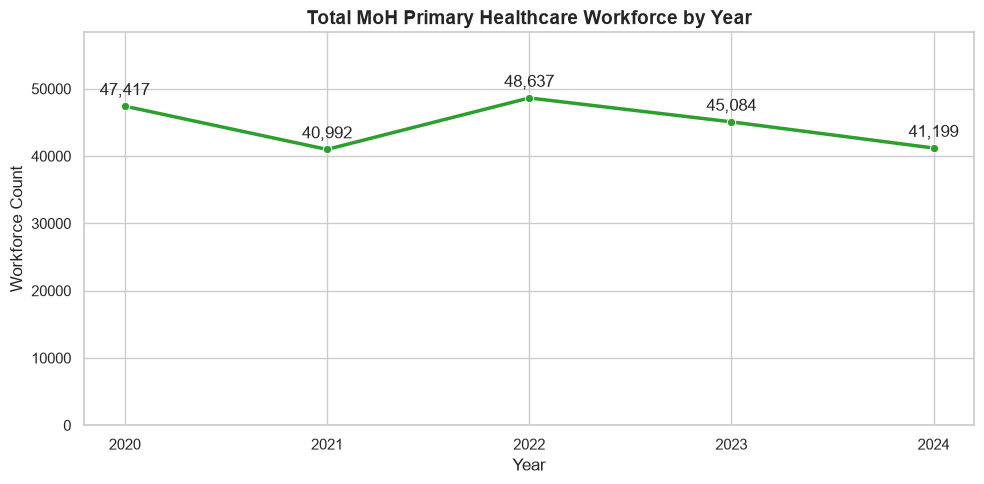

In [12]:
plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=workforce_total_trend,
    x="year",
    y="total_workforce",
    marker="o",
    linewidth=2.5,
    color="#2ca02c"
)

ax.set_title(
    "Total MoH Primary Healthcare Workforce by Year",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Workforce Count")

ax.set_xticks(
    workforce_total_trend["year"]
)

ax.set_ylim(
    0,
    workforce_total_trend["total_workforce"].max() * 1.20
)

ax.ticklabel_format(
    style="plain",
    axis="y"
)

for _, row in workforce_total_trend.iterrows():
    ax.annotate(
        f"{int(row['total_workforce']):,}",
        (
            row["year"],
            row["total_workforce"]
        ),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.tight_layout()
plt.show()

## 7. Analyze Workforce by Professional Category

Measure the change in each non-overlapping workforce category between the first and latest available years.

In [13]:
workforce_category_trend = (
    workforce_category_totals
    .sort_values(["category", "year"])
    .copy()
)

workforce_category_trend["annual_change"] = (
    workforce_category_trend
    .groupby("category")["workforce_count"]
    .diff()
)

workforce_category_trend["annual_change_pct"] = (
    workforce_category_trend
    .groupby("category")["workforce_count"]
    .pct_change()
    .mul(100)
)

workforce_category_growth = (
    workforce_category_trend
    .groupby(
        "category",
        as_index=False
    )
    .agg(
        first_year=("year", "first"),
        last_year=("year", "last"),
        first_count=("workforce_count", "first"),
        last_count=("workforce_count", "last")
    )
)

workforce_category_growth["overall_change"] = (
    workforce_category_growth["last_count"]
    - workforce_category_growth["first_count"]
)

workforce_category_growth["overall_change_pct"] = (
    workforce_category_growth["overall_change"]
    .div(workforce_category_growth["first_count"])
    .mul(100)
)

workforce_category_growth = (
    workforce_category_growth
    .sort_values(
        "overall_change_pct",
        ascending=False
    )
)

display(
    workforce_category_growth.round({
        "overall_change_pct": 2
    })
)

,category,first_year,last_year,first_count,last_count,overall_change,overall_change_pct
2,Midwives,2020,2024,228,279,51,22.37
3,Nurses,2020,2024,18169,16136,-2033,-11.19
0,Allied health Personnel,2020,2024,14059,12394,-1665,-11.84
5,Physicians,2020,2024,11351,9693,-1658,-14.61
1,Dentists,2020,2024,3043,2408,-635,-20.87
4,Pharmacists,2020,2024,567,289,-278,-49.03


### 7.1 Workforce Category Trend Visualization

Visualize workforce trends across the individual professional categories.

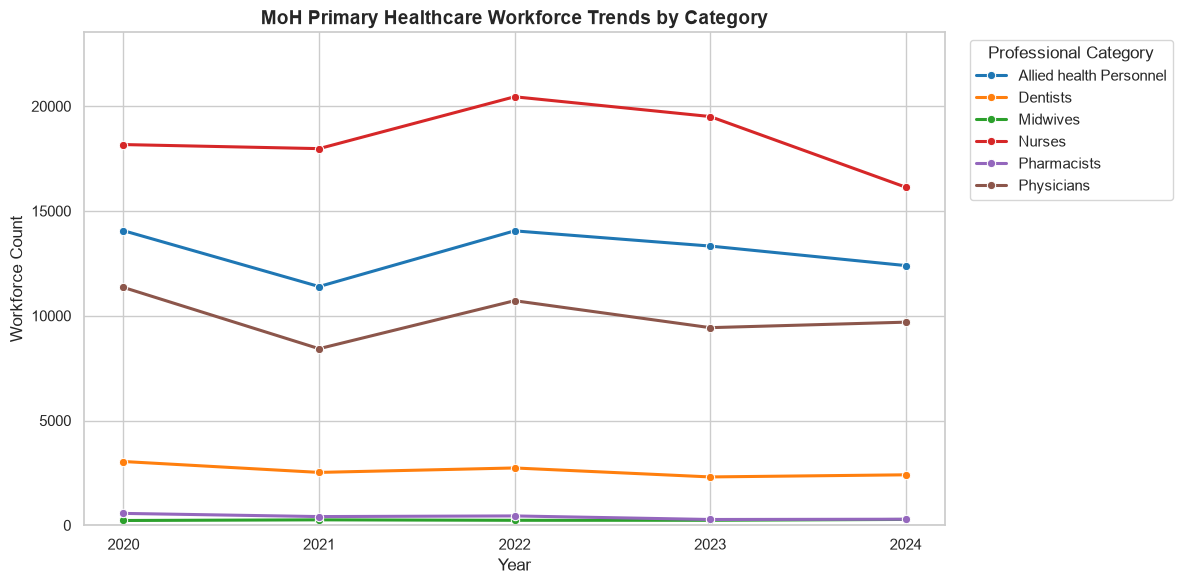

In [14]:
plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=workforce_category_trend,
    x="year",
    y="workforce_count",
    hue="category",
    marker="o",
    linewidth=2.2,
    palette="tab10"
)

ax.set_title(
    "MoH Primary Healthcare Workforce Trends by Category",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Workforce Count")

ax.set_xticks(
    sorted(workforce_category_trend["year"].unique())
)

ax.set_ylim(
    0,
    workforce_category_trend["workforce_count"].max() * 1.15
)

ax.ticklabel_format(
    style="plain",
    axis="y"
)

ax.legend(
    title="Professional Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 7.2 Workforce Category Growth Comparison

Compare the percentage change in each professional category between the first and latest available years.

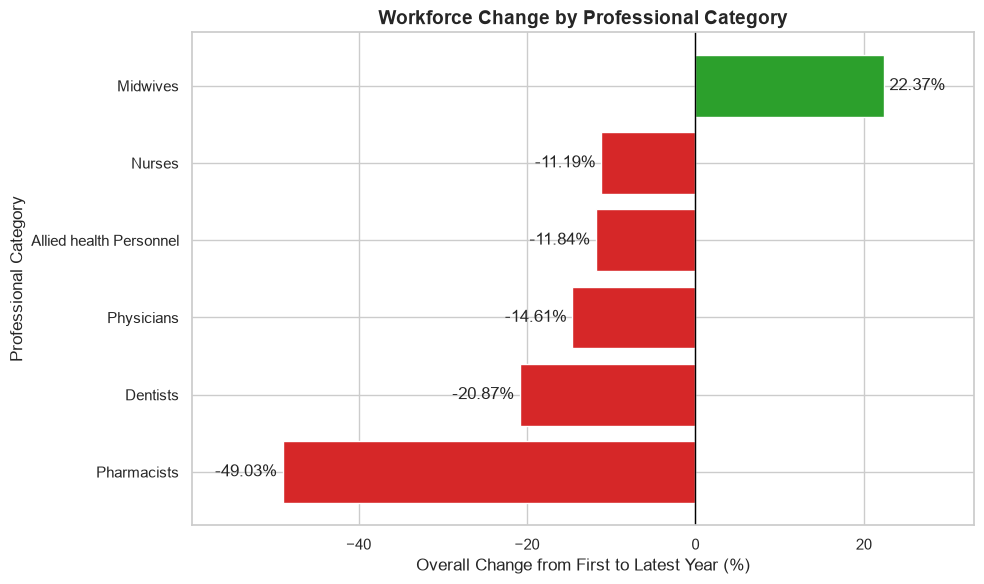

In [15]:
workforce_growth_plot = (
    workforce_category_growth
    .sort_values("overall_change_pct")
    .copy()
)

bar_colors = [
    "#2ca02c" if value >= 0 else "#d62728"
    for value in workforce_growth_plot["overall_change_pct"]
]

fig, ax = plt.subplots(
    figsize=(10, 6)
)

bars = ax.barh(
    workforce_growth_plot["category"],
    workforce_growth_plot["overall_change_pct"],
    color=bar_colors
)

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Workforce Change by Professional Category",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Overall Change from First to Latest Year (%)"
)

ax.set_ylabel(
    "Professional Category"
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

ax.margins(x=0.15)

plt.tight_layout()
plt.show()

## 8. Analyze Workforce Nationality Composition

Calculate the Saudi and Non-Saudi workforce totals and their percentage shares across years.

In [16]:
workforce_nationality_trend = (
    workforce_detail
    .groupby(
        ["year", "nationality"],
        as_index=False
    )["workforce_count"]
    .sum()
)

workforce_nationality_summary = (
    workforce_nationality_trend
    .pivot(
        index="year",
        columns="nationality",
        values="workforce_count"
    )
    .reset_index()
)

workforce_nationality_summary.columns.name = None

workforce_nationality_summary["total_workforce"] = (
    workforce_nationality_summary["Saudi"]
    + workforce_nationality_summary["Non-Saudi"]
)

workforce_nationality_summary["saudi_share_pct"] = (
    workforce_nationality_summary["Saudi"]
    .div(workforce_nationality_summary["total_workforce"])
    .mul(100)
)

workforce_nationality_summary["non_saudi_share_pct"] = (
    workforce_nationality_summary["Non-Saudi"]
    .div(workforce_nationality_summary["total_workforce"])
    .mul(100)
)

display(
    workforce_nationality_summary.round({
        "saudi_share_pct": 2,
        "non_saudi_share_pct": 2
    })
)

,year,Non-Saudi,Saudi,total_workforce,saudi_share_pct,non_saudi_share_pct
0,2020,9651,37766,47417,79.65,20.35
1,2021,7769,33223,40992,81.05,18.95
2,2022,8094,40543,48637,83.36,16.64
3,2023,6776,38308,45084,84.97,15.03
4,2024,6563,34636,41199,84.07,15.93


### 8.1 Workforce Nationality Composition Visualization

Visualize the percentage composition of Saudi and Non-Saudi workers across years.

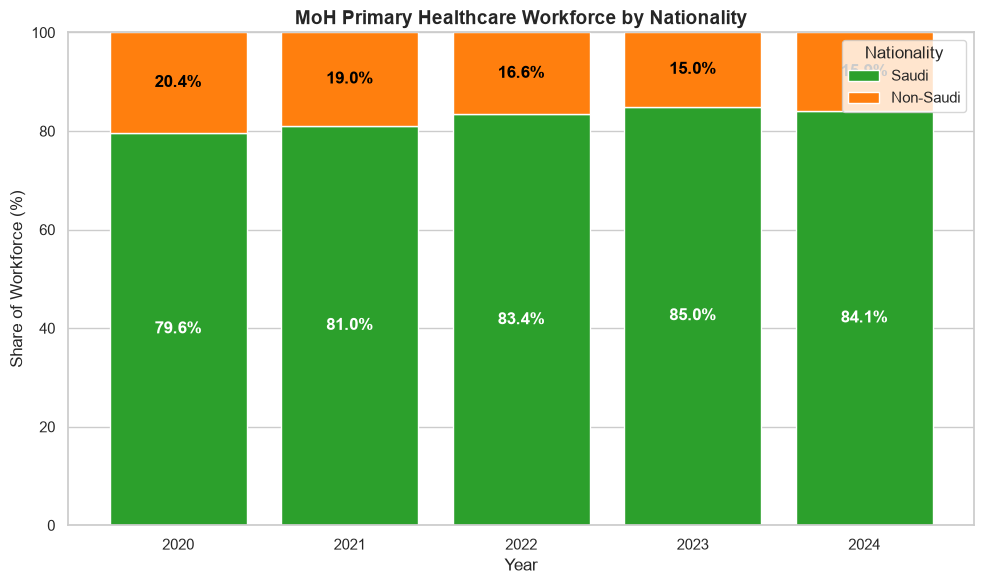

In [17]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    workforce_nationality_summary["year"],
    workforce_nationality_summary["saudi_share_pct"],
    label="Saudi",
    color="#2ca02c"
)

ax.bar(
    workforce_nationality_summary["year"],
    workforce_nationality_summary["non_saudi_share_pct"],
    bottom=workforce_nationality_summary["saudi_share_pct"],
    label="Non-Saudi",
    color="#ff7f0e"
)

ax.set_title(
    "MoH Primary Healthcare Workforce by Nationality",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Share of Workforce (%)")

ax.set_xticks(
    workforce_nationality_summary["year"]
)

ax.set_ylim(0, 100)

for _, row in workforce_nationality_summary.iterrows():
    ax.text(
        row["year"],
        row["saudi_share_pct"] / 2,
        f"{row['saudi_share_pct']:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

    ax.text(
        row["year"],
        (
            row["saudi_share_pct"]
            + row["non_saudi_share_pct"] / 2
        ),
        f"{row['non_saudi_share_pct']:.1f}%",
        ha="center",
        va="center",
        color="black",
        fontweight="bold"
    )

ax.legend(
    title="Nationality",
    loc="upper right"
)

plt.tight_layout()
plt.show()

## 9. Analyze Latest-Year Workforce Composition

Calculate the count and percentage share of each professional category in the latest available year.

In [18]:
latest_workforce_year = (
    workforce_category_totals["year"].max()
)

latest_workforce_categories = (
    workforce_category_totals[
        workforce_category_totals["year"]
        == latest_workforce_year
    ]
    .copy()
)

latest_workforce_total = (
    latest_workforce_categories["workforce_count"]
    .sum()
)

latest_workforce_categories["share_pct"] = (
    latest_workforce_categories["workforce_count"]
    .div(latest_workforce_total)
    .mul(100)
)

latest_workforce_categories = (
    latest_workforce_categories
    .sort_values(
        "workforce_count",
        ascending=False
    )
)

display(
    latest_workforce_categories.round({
        "share_pct": 2
    })
)

print(
    f"Latest workforce year: "
    f"{latest_workforce_year}"
)

print(
    f"Latest workforce total: "
    f"{latest_workforce_total:,}"
)

print(
    f"Category shares total: "
    f"{latest_workforce_categories['share_pct'].sum():.2f}%"
)

,category,nationality,year,workforce_count,share_pct
26,Nurses,Total,2024,16136,39.17
29,Allied health Personnel,Total,2024,12394,30.08
24,Physicians,Total,2024,9693,23.53
25,Dentists,Total,2024,2408,5.84
28,Pharmacists,Total,2024,289,0.70
27,Midwives,Total,2024,279,0.68


Latest workforce year: 2024
Latest workforce total: 41,199
Category shares total: 100.00%


### 9.1 Latest-Year Workforce Composition Visualization

Visualize the size and percentage share of each professional category in the latest available year.

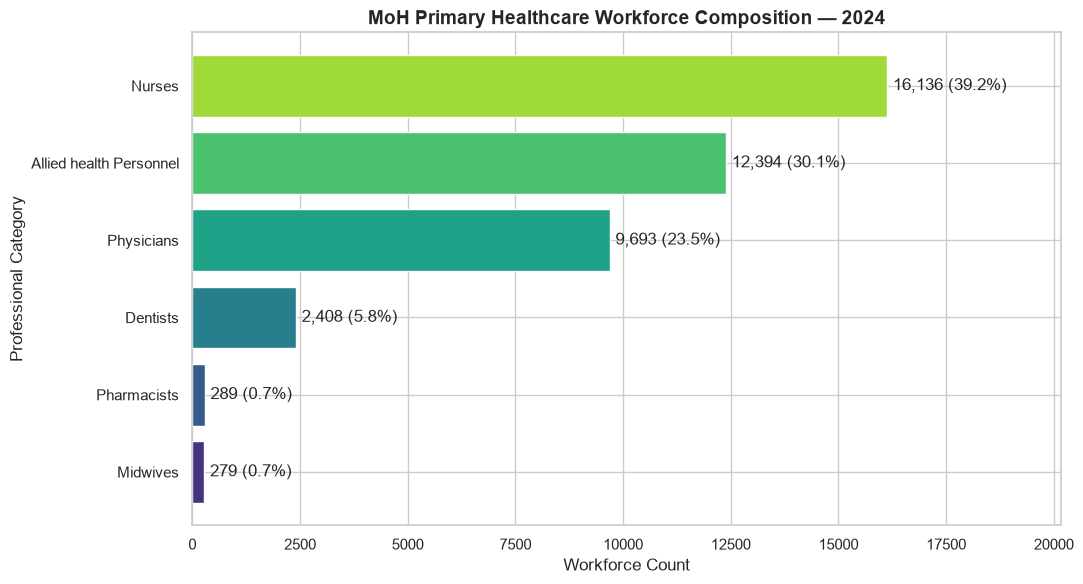

In [19]:
latest_workforce_plot = (
    latest_workforce_categories
    .sort_values("workforce_count")
    .copy()
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

bars = ax.barh(
    latest_workforce_plot["category"],
    latest_workforce_plot["workforce_count"],
    color=sns.color_palette(
        "viridis",
        n_colors=len(latest_workforce_plot)
    )
)

ax.set_title(
    f"MoH Primary Healthcare Workforce Composition — "
    f"{latest_workforce_year}",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Workforce Count")
ax.set_ylabel("Professional Category")

ax.ticklabel_format(
    style="plain",
    axis="x"
)

bar_labels = [
    f"{int(count):,} ({share:.1f}%)"
    for count, share in zip(
        latest_workforce_plot["workforce_count"],
        latest_workforce_plot["share_pct"]
    )
]

ax.bar_label(
    bars,
    labels=bar_labels,
    padding=4
)

ax.margins(x=0.25)

plt.tight_layout()
plt.show()

## 10. Contextual Trend Comparison

Compare the relative change in total inpatients and the MoH primary healthcare workforce using a base-year index.

> Important: The two datasets cover different healthcare scopes. This comparison describes relative trends only and must not be interpreted as a direct workload ratio or a causal relationship.

In [20]:
contextual_trends = pd.merge(
    inpatient_total_trend[
        ["year", "total_inpatients"]
    ],
    workforce_total_trend[
        ["year", "total_workforce"]
    ],
    on="year",
    how="inner"
).sort_values("year")

base_inpatients = (
    contextual_trends["total_inpatients"].iloc[0]
)

base_workforce = (
    contextual_trends["total_workforce"].iloc[0]
)

contextual_trends["inpatient_index"] = (
    contextual_trends["total_inpatients"]
    .div(base_inpatients)
    .mul(100)
)

contextual_trends["workforce_index"] = (
    contextual_trends["total_workforce"]
    .div(base_workforce)
    .mul(100)
)

display(
    contextual_trends.round({
        "inpatient_index": 2,
        "workforce_index": 2
    })
)

,year,total_inpatients,total_workforce,inpatient_index,workforce_index
0,2020,2846773,47417,100.00,100.00
1,2021,3100752,40992,108.92,86.45
2,2022,2702460,48637,94.93,102.57
3,2023,3831824,45084,134.60,95.08
4,2024,3630334,41199,127.52,86.89


### 10.1 Indexed Trend Visualization

Visualize the relative changes in inpatient totals and the MoH primary healthcare workforce using a common base-year index.

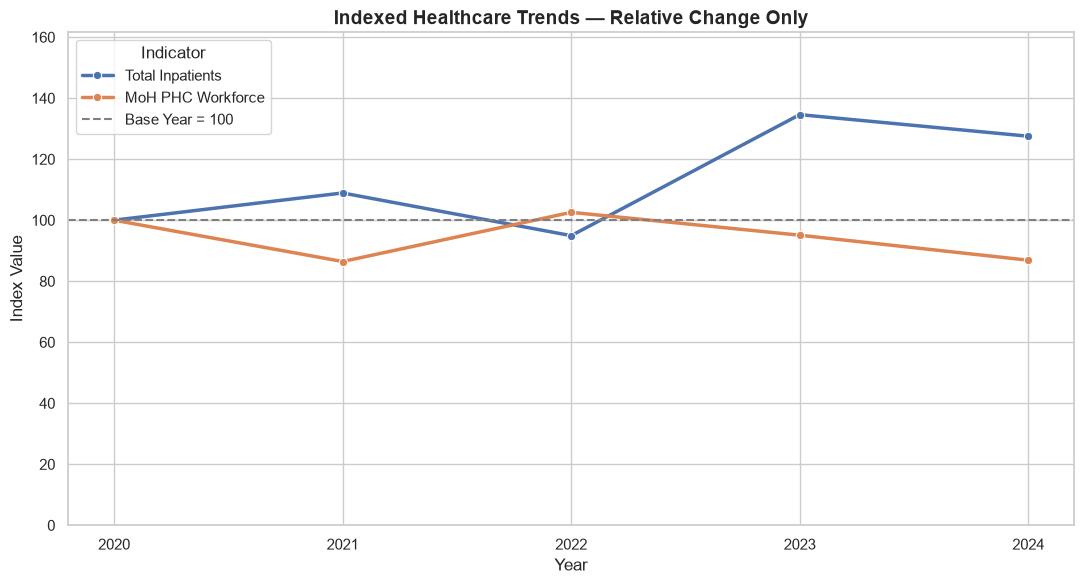

In [21]:
contextual_trends_long = (
    contextual_trends[
        [
            "year",
            "inpatient_index",
            "workforce_index"
        ]
    ]
    .melt(
        id_vars="year",
        var_name="indicator",
        value_name="index_value"
    )
)

contextual_trends_long["indicator"] = (
    contextual_trends_long["indicator"]
    .replace({
        "inpatient_index": "Total Inpatients",
        "workforce_index": "MoH PHC Workforce"
    })
)

plt.figure(figsize=(11, 6))

ax = sns.lineplot(
    data=contextual_trends_long,
    x="year",
    y="index_value",
    hue="indicator",
    marker="o",
    linewidth=2.5
)

ax.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Base Year = 100"
)

ax.set_title(
    "Indexed Healthcare Trends — Relative Change Only",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Index Value")

ax.set_xticks(
    sorted(contextual_trends_long["year"].unique())
)

ax.set_ylim(
    0,
    contextual_trends_long["index_value"].max() * 1.20
)

ax.legend(
    title="Indicator"
)

plt.tight_layout()
plt.show()

## 11. Key Analytical Indicators

Summarize the most important inpatient, admission-rate, and workforce findings identified during the exploratory analysis.

In [22]:
valid_inpatient_changes = (
    inpatient_total_trend
    .dropna(subset=["annual_change_pct"])
)

largest_inpatient_increase = valid_inpatient_changes.loc[
    valid_inpatient_changes[
        "annual_change_pct"
    ].idxmax()
]

largest_inpatient_decrease = valid_inpatient_changes.loc[
    valid_inpatient_changes[
        "annual_change_pct"
    ].idxmin()
]

fastest_growing_category = workforce_category_growth.loc[
    workforce_category_growth[
        "overall_change_pct"
    ].idxmax()
]

lowest_growth_category = workforce_category_growth.loc[
    workforce_category_growth[
        "overall_change_pct"
    ].idxmin()
]

latest_nationality_summary = (
    workforce_nationality_summary
    .sort_values("year")
    .iloc[-1]
)

key_indicators = pd.DataFrame([
    {
        "indicator": "Overall inpatient change",
        "value": round(
            float(overall_change_pct),
            2
        ),
        "unit": "percent",
        "context": (
            f"{int(first_year)} to "
            f"{int(last_year)}"
        )
    },
    {
        "indicator": "Largest annual inpatient increase",
        "value": round(
            float(
                largest_inpatient_increase[
                    "annual_change_pct"
                ]
            ),
            2
        ),
        "unit": "percent",
        "context": str(
            int(largest_inpatient_increase["year"])
        )
    },
    {
        "indicator": "Largest annual inpatient decrease",
        "value": round(
            float(
                largest_inpatient_decrease[
                    "annual_change_pct"
                ]
            ),
            2
        ),
        "unit": "percent",
        "context": str(
            int(largest_inpatient_decrease["year"])
        )
    },
    {
        "indicator": "Highest admission rate",
        "value": round(
            float(
                highest_rate_row[
                    "admissions_per_100"
                ]
            ),
            1
        ),
        "unit": "admissions per 100 persons",
        "context": str(
            int(highest_rate_row["year"])
        )
    },
    {
        "indicator": "Overall workforce change",
        "value": round(
            float(workforce_overall_change_pct),
            2
        ),
        "unit": "percent",
        "context": (
            f"{int(workforce_total_trend['year'].iloc[0])} "
            f"to "
            f"{int(workforce_total_trend['year'].iloc[-1])}"
        )
    },
    {
        "indicator": "Fastest-growing workforce category",
        "value": round(
            float(
                fastest_growing_category[
                    "overall_change_pct"
                ]
            ),
            2
        ),
        "unit": "percent",
        "context": str(
            fastest_growing_category["category"]
        )
    },
    {
        "indicator": "Lowest-growth workforce category",
        "value": round(
            float(
                lowest_growth_category[
                    "overall_change_pct"
                ]
            ),
            2
        ),
        "unit": "percent",
        "context": str(
            lowest_growth_category["category"]
        )
    },
    {
        "indicator": "Latest Saudi workforce share",
        "value": round(
            float(
                latest_nationality_summary[
                    "saudi_share_pct"
                ]
            ),
            2
        ),
        "unit": "percent",
        "context": str(
            int(latest_nationality_summary["year"])
        )
    }
])

display(key_indicators)

,indicator,value,unit,context
0,Overall inpatient change,27.52,percent,2020 to 2024
1,Largest annual inpatient increase,41.79,percent,2023
2,Largest annual inpatient decrease,-12.85,percent,2022
3,Highest admission rate,11.30,admissions per 100 persons,2023
4,Overall workforce change,-13.11,percent,2020 to 2024
5,Fastest-growing workforce category,22.37,percent,Midwives
6,Lowest-growth workforce category,-49.03,percent,Pharmacists
7,Latest Saudi workforce share,84.07,percent,2024


## 12. Analyze Nationality Composition by Professional Category

Compare the Saudi and Non-Saudi workforce composition within each professional category in the latest available year.

In [23]:
latest_workforce_detail = (
    workforce_detail[
        workforce_detail["year"]
        == latest_workforce_year
    ]
    .copy()
)

latest_category_nationality = (
    latest_workforce_detail
    .pivot(
        index="category",
        columns="nationality",
        values="workforce_count"
    )
    .reset_index()
)

latest_category_nationality.columns.name = None

latest_category_nationality["total_workforce"] = (
    latest_category_nationality["Saudi"]
    + latest_category_nationality["Non-Saudi"]
)

latest_category_nationality["saudi_share_pct"] = (
    latest_category_nationality["Saudi"]
    .div(latest_category_nationality["total_workforce"])
    .mul(100)
)

latest_category_nationality["non_saudi_share_pct"] = (
    latest_category_nationality["Non-Saudi"]
    .div(latest_category_nationality["total_workforce"])
    .mul(100)
)

latest_category_nationality = (
    latest_category_nationality
    .sort_values(
        "saudi_share_pct",
        ascending=False
    )
)

display(
    latest_category_nationality.round({
        "saudi_share_pct": 2,
        "non_saudi_share_pct": 2
    })
)

,category,Non-Saudi,Saudi,total_workforce,saudi_share_pct,non_saudi_share_pct
0,Allied health Personnel,84,12310,12394,99.32,0.68
1,Dentists,20,2388,2408,99.17,0.83
4,Pharmacists,4,285,289,98.62,1.38
2,Midwives,26,253,279,90.68,9.32
3,Nurses,1991,14145,16136,87.66,12.34
5,Physicians,4438,5255,9693,54.21,45.79


### 12.1 Category Nationality Composition Visualization

Visualize the Saudi and Non-Saudi percentage composition within each professional category in the latest available year.

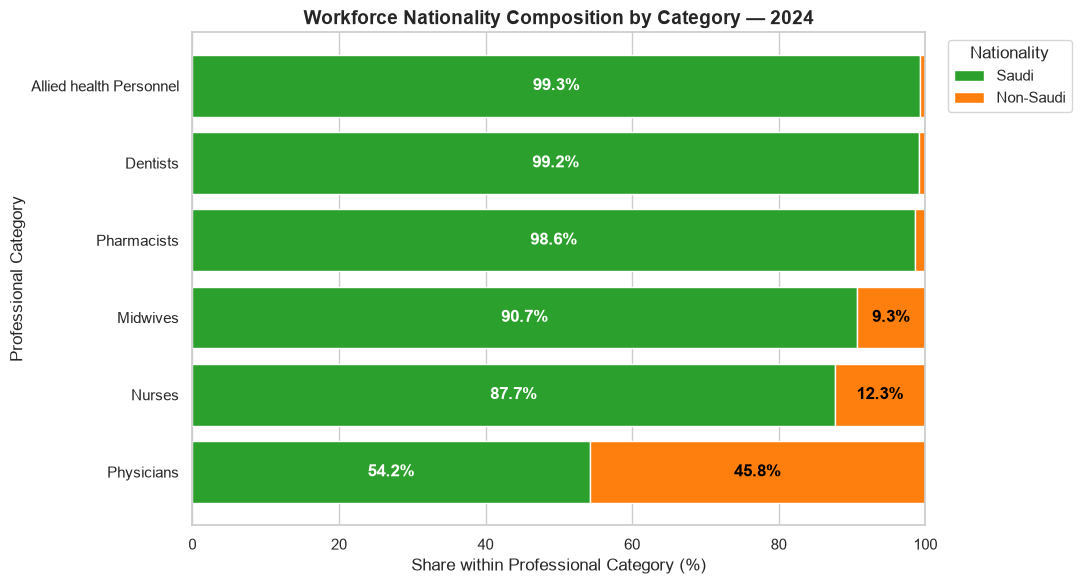

In [24]:
category_nationality_plot = (
    latest_category_nationality
    .sort_values("saudi_share_pct")
    .copy()
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.barh(
    category_nationality_plot["category"],
    category_nationality_plot["saudi_share_pct"],
    label="Saudi",
    color="#2ca02c"
)

ax.barh(
    category_nationality_plot["category"],
    category_nationality_plot["non_saudi_share_pct"],
    left=category_nationality_plot["saudi_share_pct"],
    label="Non-Saudi",
    color="#ff7f0e"
)

ax.set_title(
    f"Workforce Nationality Composition by Category — "
    f"{latest_workforce_year}",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Share within Professional Category (%)")
ax.set_ylabel("Professional Category")

ax.set_xlim(0, 100)

for position, (_, row) in enumerate(
    category_nationality_plot.iterrows()
):
    ax.text(
        row["saudi_share_pct"] / 2,
        position,
        f"{row['saudi_share_pct']:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

    if row["non_saudi_share_pct"] >= 5:
        ax.text(
            (
                row["saudi_share_pct"]
                + row["non_saudi_share_pct"] / 2
            ),
            position,
            f"{row['non_saudi_share_pct']:.1f}%",
            ha="center",
            va="center",
            color="black",
            fontweight="bold"
        )

ax.legend(
    title="Nationality",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## 13. Analysis Limitations

- The available data covers only five annual observations from 2020 to 2024.
- The datasets contain aggregated statistics rather than patient-level or facility-level records.
- The inpatient dataset covers hospital sectors, while the workforce dataset covers Ministry of Health primary healthcare workforce records.
- Direct patient-to-workforce workload ratios are not calculated because the two datasets represent different healthcare scopes.
- Indexed comparisons describe relative trends only and do not establish a direct operational relationship.
- Observed increases or decreases do not prove causation.
- National totals may hide important differences between regions, facilities, specialties, and population groups.
- Hospital admissions represent admission events and may include repeated admissions for the same person.
- Forecasting reliability will remain limited until additional years or more granular time periods become available.
- Future data sources should be validated for changes in definitions, measurement units, categories, and reporting coverage before being combined with the current datasets.

## 14. Save Analytical Outputs

Save the main analytical summary tables for reporting, dashboards, and future decision-support components.

In [25]:
eda_output_dir = (
    project_root
    / "outputs"
    / "eda"
)

eda_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

analysis_outputs = {
    "key_indicators": key_indicators,
    "inpatient_total_trend": inpatient_total_trend,
    "workforce_category_growth": workforce_category_growth,
    "contextual_index_trends": contextual_trends
}

saved_analysis_files = []

for output_name, dataframe in analysis_outputs.items():
    output_path = eda_output_dir / f"{output_name}.csv"

    dataframe.to_csv(
        output_path,
        index=False
    )

    saved_analysis_files.append(output_path)

print("Saved analytical outputs:")

for output_path in saved_analysis_files:
    print("-", output_path)

Saved analytical outputs:
- c:\Users\Am132\Projects\healthcare-ai-agent\outputs\eda\key_indicators.csv
- c:\Users\Am132\Projects\healthcare-ai-agent\outputs\eda\inpatient_total_trend.csv
- c:\Users\Am132\Projects\healthcare-ai-agent\outputs\eda\workforce_category_growth.csv
- c:\Users\Am132\Projects\healthcare-ai-agent\outputs\eda\contextual_index_trends.csv


## 15. Exploratory Analysis Summary

- Six validated processed datasets were loaded successfully.
- Total inpatient counts were analyzed across the available years.
- Annual inpatient changes and overall percentage change were calculated.
- Inpatient trends were compared across healthcare sectors.
- The latest-year inpatient distribution was calculated for each sector.
- Hospital admissions per 100 persons were analyzed and compared with the period average.
- Total Ministry of Health primary healthcare workforce trends were analyzed.
- Workforce growth was compared across non-overlapping professional categories.
- Saudi and Non-Saudi workforce composition was analyzed across years.
- The latest workforce composition was evaluated by professional category.
- Nationality composition was compared within each professional category.
- Inpatient and workforce trends were compared using base-year indices rather than a direct workload ratio.
- Key analytical indicators were generated programmatically.
- The analysis identified trends and notable changes without claiming causal relationships.
- Four analytical summary files were saved in `outputs/eda`.
- The results are ready for later use in reporting, SQL, Power BI, forecasting, and decision-support components.